<a href="https://colab.research.google.com/github/khushi78vaish/Covid19_data_analysis/blob/main/Fake.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install pandas numpy scikit-learn nltk transformers

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving Fake.csv to Fake (1).csv


In [ ]:
from google.colab import files
uploaded = files.upload()

Saving True.csv.zip to True.csv (1).zip


In [ ]:
import pandas as pd

# Load the uploaded files
fake_news = pd.read_csv("Fake.csv")
real_news = pd.read_csv("True.csv")

# Verify the data
print("Fake News Head:")
print(fake_news.head())
print("\nReal News Head:")
print(real_news.head())

Fake News Head:
                                               title  \
0   Donald Trump Sends Out Embarrassing New Year’...   
1   Drunk Bragging Trump Staffer Started Russian ...   
2   Sheriff David Clarke Becomes An Internet Joke...   
3   Trump Is So Obsessed He Even Has Obama’s Name...   
4   Pope Francis Just Called Out Donald Trump Dur...   

                                                text subject  \
0  Donald Trump just couldn t wish all Americans ...    News   
1  House Intelligence Committee Chairman Devin Nu...    News   
2  On Friday, it was revealed that former Milwauk...    News   
3  On Christmas day, Donald Trump announced that ...    News   
4  Pope Francis used his annual Christmas Day mes...    News   

                date  
0  December 31, 2017  
1  December 31, 2017  
2  December 30, 2017  
3  December 29, 2017  
4  December 25, 2017  

Real News Head:
                                               title  \
0  As U.S. budget fight looms, Republicans flip t..

In [ ]:
# Add labels
fake_news['label'] = 0  # 0 = Fake
real_news['label'] = 1   # 1 = Real

# Combine and shuffle the data
data = pd.concat([fake_news, real_news]).sample(frac=1).reset_index(drop=True)

# Check the distribution
print("\nLabel counts:")
print(data['label'].value_counts())# Add labels
fake_news['label'] = 0  # 0 = Fake
real_news['label'] = 1   # 1 = Real

# Combine and shuffle the data
data = pd.concat([fake_news, real_news]).sample(frac=1).reset_index(drop=True)

# Check the distribution
print("\nLabel counts:")
print(data['label'].value_counts())


Label counts:
label
0    23481
1    21417
Name: count, dtype: int64

Label counts:
label
0    23481
1    21417
Name: count, dtype: int64


In [ ]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

nltk.download('stopwords')  # Download stopwords list
stop_words = set(stopwords.words('english'))
stemmer = PorterStemmer()

def clean_text(text):
    # Lowercase
    text = text.lower()
    # Remove URLs
    text = re.sub(r'http\S+|www\S+|https\S+', '', text, flags=re.MULTILINE)
    # Remove punctuation and special chars
    text = re.sub(r'[^\w\s]', '', text)
    # Remove stopwords and stem
    words = text.split()
    words = [stemmer.stem(word) for word in words if word not in stop_words]
    return ' '.join(words)

# Apply cleaning to the 'text' column
data['cleaned_text'] = data['text'].apply(clean_text)

# Check cleaned text
print("\nCleaned Text Example:")
print(data['cleaned_text'][0])

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.



Cleaned Text Example:
women fox news sick tire put sexist bullshit male colleagu bossesaft gretchen carlson file sexual harass lawsuit roger ail becam clear sexism misogyni ran deeper within compani anyon realiz turn went way beyond onair comment made male anchor like bill reillyonc megyn kelli back carlson ail creek without paddl soon oust posit scandal rock conserv network former femal report came forward tell stori nonstop harass turn workplac person helland carlson one file lawsuit andrea tantaro welltantaro file lawsuit new york state suprem court monday hammer network punish went top brass complain ail sexual harass fox news masquerad defend tradit famili valu behind scene oper like sexfuel playboy mansionlik cult steep intimid indec misogyni lawsuit say accord new york time turn tantaro also name bill reilli lawsuit make unwant advanc toward herfox execut attempt pay tantaro renounc claim told go fck themselvesth lawsuit detail roger ail treat includ bar wear pant set ail want 

In [ ]:
import numpy as np  # Add this line at the beginning

In [ ]:
import numpy as np  # Required for np.array()
from transformers import BertTokenizer, BertModel
import torch

tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')
model = BertModel.from_pretrained('bert-base-uncased')

def bert_embed(text):
    inputs = tokenizer(text, return_tensors='pt', truncation=True, max_length=512)
    outputs = model(**inputs)
    return outputs.last_hidden_state.mean(dim=1).detach().numpy()

# Convert BERT embeddings to NumPy array
X_bert = np.array([bert_embed(text)[0] for text in data['cleaned_text'].head(100)])  # 100 samples
y_bert = data['label'].head(100)

In [ ]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression()
model.fit(X_bert, y_bert)

LogisticRegression()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Split data into train/test sets
X_train, X_test, y_train, y_test = train_test_split(
    X_bert, y_bert, test_size=0.2, random_state=42
)

# Train a classifier (Logistic Regression is lightweight)
clf = LogisticRegression(max_iter=1000)
clf.fit(X_train, y_train)

# Evaluate
y_pred = clf.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.9

Classification Report:
              precision    recall  f1-score   support

           0       0.83      1.00      0.91        10
           1       1.00      0.80      0.89        10

    accuracy                           0.90        20
   macro avg       0.92      0.90      0.90        20
weighted avg       0.92      0.90      0.90        20



In [ ]:
import joblib
from transformers import BertTokenizer, BertModel

# 1. Save your scikit-learn classifier
joblib.dump(clf, 'bert_logistic_regression.pkl')

# 2. Save BERT components PROPERLY
tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')
model = BertModel.from_pretrained('bert-base-uncased')

# Create directories if they don't exist
!mkdir -p bert_tokenizer
!mkdir -p bert_model

# Save with Hugging Face's built-in methods
tokenizer.save_pretrained("bert_tokenizer")
model.save_pretrained("bert_model")

print("All components saved successfully!")

All components saved successfully!


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Load classifier
clf = joblib.load('bert_logistic_regression.pkl')

# Load BERT components
from transformers import BertTokenizer, BertModel
tokenizer = BertTokenizer.from_pretrained("bert_tokenizer")
model = BertModel.from_pretrained("bert_model")

In [ ]:
!mkdir -p fake_news_model

# Save all components
joblib.dump(clf, 'fake_news_model/classifier.pkl')
tokenizer.save_pretrained("fake_news_model/tokenizer")
model.save_pretrained("fake_news_model/bert")

# Zip for download
!zip -r fake_news_model.zip fake_news_model

  adding: fake_news_model/ (stored 0%)
  adding: fake_news_model/bert/ (stored 0%)
  adding: fake_news_model/bert/model.safetensors (deflated 7%)
  adding: fake_news_model/bert/config.json (deflated 48%)
  adding: fake_news_model/tokenizer/ (stored 0%)
  adding: fake_news_model/tokenizer/vocab.txt (deflated 53%)
  adding: fake_news_model/tokenizer/special_tokens_map.json (deflated 80%)
  adding: fake_news_model/tokenizer/tokenizer_config.json (deflated 75%)
  adding: fake_news_model/classifier.pkl (deflated 6%)


In [ ]:
# Save a smaller version
model.save_pretrained("bert_model", use_safetensors=True)

In [ ]:
torch.save(model.state_dict(), "bert_model/pytorch_model.bin")

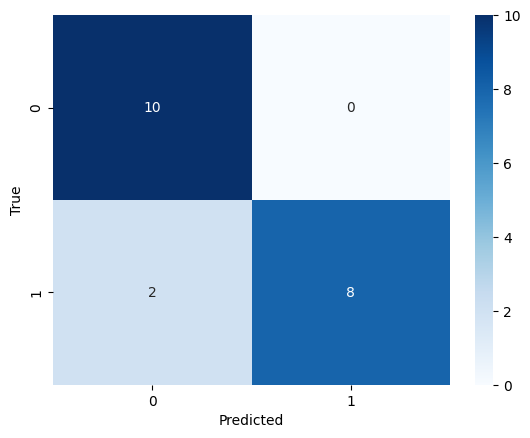

ROC-AUC: 0.96


In [ ]:
from sklearn.metrics import confusion_matrix, roc_auc_score
import seaborn as sns
import matplotlib.pyplot as plt

# Generate predictions
y_proba = clf.predict_proba(X_test)[:, 1]  # Probability of being "Real"
y_pred = clf.predict(X_test)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

# ROC-AUC Score
print(f"ROC-AUC: {roc_auc_score(y_test, y_proba):.2f}")

In [ ]:
def predict_news(text):
    # Preprocess
    text = clean_text(text)

    # BERT Embedding
    inputs = tokenizer(text, return_tensors='pt', truncation=True, max_length=512)
    with torch.no_grad():
        outputs = model(**inputs)
    embedding = outputs.last_hidden_state.mean(dim=1).numpy()

    # Predict
    proba = clf.predict_proba(embedding)[0]
    return {
        "prediction": "Real" if clf.predict(embedding)[0] == 1 else "Fake",
        "confidence": max(proba)
    }

# Test
predict_news("NASA confirms aliens exist!")  # Example

{'prediction': 'Fake', 'confidence': np.float64(0.896303646090597)}

In [ ]:
!pip install gradio

import gradio as gr
gr.Interface(
    fn=predict_news,
    inputs="text",
    outputs=["label", "number"]
).launch()

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 MB 11.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 322.2/322.2 kB 31.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.2/95.2 kB 10.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 103.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.0/72.0 kB 8.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.4/62.4 kB 7.0 MB/s eta 0:00:00
It looks like you are running Gradio on a hosted a Jupyter notebook. For the Gradio app to work, sharing must be enabled. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://c7dcd1ee3122d6142f.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working director

In [ ]:
# Example test cases
test_cases = [
    "The moon landing was faked by NASA",  # Should predict "Fake"
    "Scientists confirm climate change is real"  # Should predict "Real"
]
for text in test_cases:
    print(f"Input: {text}\nOutput: {predict_news(text)}\n")

Input: The moon landing was faked by NASA
Output: {'prediction': 'Fake', 'confidence': np.float64(0.8423198490497121)}

Input: Scientists confirm climate change is real
Output: {'prediction': 'Real', 'confidence': np.float64(0.8118777769592294)}



In [ ]:
!pip install huggingface_hub
from huggingface_hub import notebook_login
notebook_login()
!gradio deploy

Need 'write' access token to create a Spaces repo.

    _|    _|  _|    _|    _|_|_|    _|_|_|  _|_|_|  _|      _|    _|_|_|      _|_|_|_|    _|_|      _|_|_|  _|_|_|_|
    _|    _|  _|    _|  _|        _|          _|    _|_|    _|  _|            _|        _|    _|  _|        _|
    _|_|_|_|  _|    _|  _|  _|_|  _|  _|_|    _|    _|  _|  _|  _|  _|_|      _|_|_|    _|_|_|_|  _|        _|_|_|
    _|    _|  _|    _|  _|    _|  _|    _|    _|    _|    _|_|  _|    _|      _|        _|    _|  _|        _|
    _|    _|    _|_|      _|_|_|    _|_|_|  _|_|_|  _|      _|    _|_|_|      _|        _|    _|    _|_|_|  _|_|_|_|

Enter your token (input will not be visible): 